# Ablations, independent seeds and unseen distances

Joint inverse training is compared with data-only learning and a physics-only forward problem with coefficients already known. Unknown-coefficient inverse inference without observations is underdetermined.

All measurements here are synthetic. This notebook runs a small independent calculation and then inspects a retained study figure. It does not launch full training or overwrite the saved scientific results.

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/optics_portfolio").exists())
%matplotlib inline

PROJECT = ROOT


## Calculate and inspect

Read the calculation before executing. Compare numerical values with the stated physical assumptions.

In [2]:
metrics=json.loads((PROJECT/"results/advanced_metrics.json").read_text())
print(json.dumps(metrics["ablation_summary"],indent=2))
print("Classical unseen pulse error:",metrics["classical_unseen_pulse_error"])
print("Median same-grid forward timings:",metrics["forward_timing_median_seconds"])

{
  "joint_inverse": {
    "n": 3,
    "mean": 0.01244747322112152,
    "std": 0.00219757957318675,
    "minimum": 0.010389152807344853,
    "maximum": 0.014761874178282092
  },
  "data_only": {
    "n": 3,
    "mean": 0.011350695277319035,
    "std": 0.00043690475980543385,
    "minimum": 0.010900280660886622,
    "maximum": 0.011772703942539393
  },
  "physics_only_known_coefficients": {
    "n": 1,
    "mean": 0.032508535212504304,
    "std": 0.0,
    "minimum": 0.032508535212504304,
    "maximum": 0.032508535212504304
  }
}
Classical unseen pulse error: 0.0023480816306771313
Median same-grid forward timings: {'ssfm': 0.08589749998645857, 'pinn': 0.0015302000101655722}


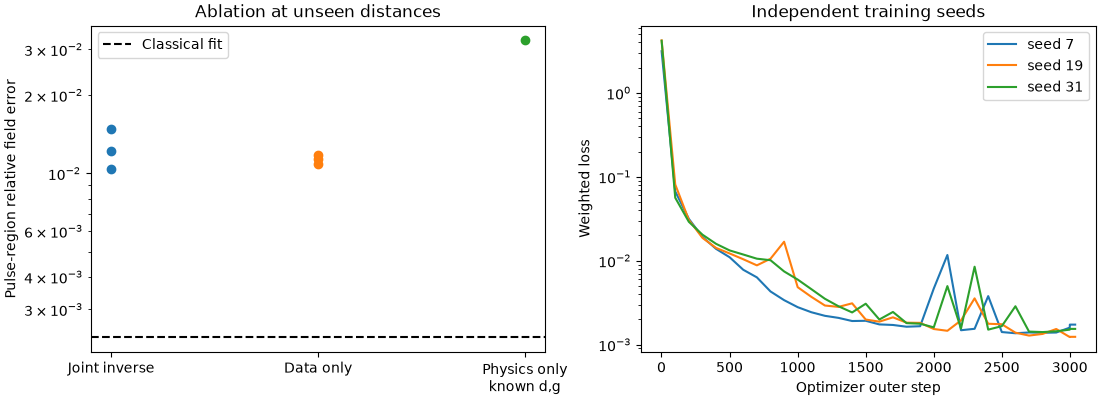

In [3]:
display(Image(filename=str(PROJECT / "results/ablation.png")))

## Interpret and extend

Do the PINN seeds support a stable conclusion? Why must inference time and training time be separated? Explain why unseen distances within the training interval are interpolation rather than extrapolation.

See `../report/technical_report.md` and the project README for the full experiment and limitations. Record your own changed settings and conclusions in a separate run.